# 04-1. 결빙 분류: 후보 모델과 교차검증

10분 단위로 결빙 여부를 예측하는 모델을 고릅니다. 04의 0~1장이며, Ice 라벨의 특성을 본 뒤 후보 모델을 지점 단위 교차검증으로 비교해서 최종 모델과 임계값을 정합니다.

평가 기준은 문제 설명과 주최 측 QnA 답변을 따릅니다.

- 노면상태 Ice는 결빙, 그 외 유효한 상태는 비결빙입니다 (2026-10-07). 노면상태 0·-999는 평가에서 뺍니다 (2026-09-30).
- 일(00:00~23:50)별로 TP, FP, FN을 세어 F1, Precision, Recall을 구하고 평가기간 평균을 냅니다. 시각은 10분 단위로 정확히 맞아야 합니다 (2026-11-02).
- 실제·예측 결빙이 모두 없는 날은 평균에서 뺍니다 (2026-09-30). 결빙을 놓친 날은 Precision을, 예측만 한 날은 Recall을 평균에서 뺍니다 (2026-10-13·11-03).
- 지점별 평균과 세 지점 평균을 제시합니다 (2026-09-29). 실제 결빙이 한 번도 없는 지점은 '산출불가'로 적고 평균에서 뺍니다 (2026-11-02·11-03).

검증 지점은 미관측 지점으로 봅니다. 그 지점의 실측값(노면온도, 노면상태)은 입력으로 쓰지 않습니다. 다른 학습 지점의 같은 시각 노면상태도 쓸 수 없습니다 (QnA 2026-11-02). 입력은 03-3의 추정 노면온도, 02-2의 보간 기상, 주변 RWIS 노면온도입니다.

최종 모델은 `model/icing_*`에, 교차검증 확률과 설정은 `data/processed/icing_*`에, 교차검증 성능과 변수 중요도는 `data/results/`에 저장합니다.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parents[1]  # notebooks/<단계 폴더>/ 에서 실행
sys.path.insert(0, str(ROOT))

from src import config

In [2]:
import json
import time
import warnings

import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cycler import cycler
from matplotlib import font_manager
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

for font in ["NanumGothic", "Malgun Gothic", "AppleGothic"]:
    if any(f.name == font for f in font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = font
        break
plt.rcParams.update({
    "axes.unicode_minus": False,
    "axes.prop_cycle": cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                                     "#e87ba4", "#008300", "#4a3aa7", "#e34948"]),
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "figure.dpi": 100, "lines.linewidth": 1.5,
})
SEED = 42

In [3]:
sf = pd.read_parquet(config.PROCESSED_DIR / "station_features.parquet")
sf = sf.merge(pd.read_parquet(config.PROCESSED_DIR / "station_estimates.parquet"), on=["stn", "time"])
stations = pd.read_parquet(config.PROCESSED_DIR / "stations.parquet").set_index("stn")
meta = json.load(open(config.PROCESSED_DIR / "features.json", encoding="utf-8"))

sf["rst_dpd"] = sf["rst_est"] - sf["td"]  # 추정 노면온도 - 이슬점: 음수면 노면에 서리·응결이 생길 수 있다
sf["date"] = sf["time"].dt.normalize()
print(sf.shape, "Ice:", int(sf["ice"].sum()), "라벨 없음:", int(sf["ice"].isna().sum()))

(587520, 50) Ice: 303 라벨 없음: 4162


## 0. Ice 라벨의 특성

모델을 만들기 전에 Ice가 시간적으로 어떻게 나타나는지 확인했습니다.

In [4]:
runs, around = [], []
for stn, g in sf.sort_values(["stn", "time"]).groupby("stn"):
    x = (g["ice"] == 1).to_numpy().astype(int)
    edge = np.diff(np.r_[0, x, 0])
    runs += list(np.flatnonzero(edge == -1) - np.flatnonzero(edge == 1))
    states = g["state"].to_numpy()
    for i in np.flatnonzero(x):
        around += [s for s in states[max(i - 3, 0):i + 4] if s != 4 and not np.isnan(s)]
print("Ice 연속 길이(10분 단위) 분포:", pd.Series(runs).value_counts().sort_index().to_dict())
STATE_NAMES = {1: "Dry", 2: "Wet", 3: "Snow", 4: "Ice", 10: "저시정", 11: "물고임", 12: "Damp+저온(제빙)",
               13: "결빙시작(제빙)", 14: "Damp", 15: "판별불가"}
print("Ice 앞뒤 30분의 다른 노면상태:")
print(pd.Series(around).map(STATE_NAMES).value_counts().to_string())

Ice 연속 길이(10분 단위) 분포: {1: 248, 2: 18, 3: 5, 4: 1}
Ice 앞뒤 30분의 다른 노면상태:
Damp+저온(제빙)    574
판별불가           406
Dry            234
Wet            202
Snow           164
Damp            70
결빙시작(제빙)        34


Ice는 대부분 10분 한 번 나타나고 바로 다른 상태로 바뀝니다(연속 1회가 90% 이상). 앞뒤로는 Damp+저온(12), 판별불가(15), Snow(3)가 많습니다. 젖은 노면이 어는 수십 분~수 시간 동안 센서 판정이 비슷한 상태 사이를 오가는 것으로 보입니다.

10분 단위로 맞히기가 얼마나 어려운지 보려고 그 지점의 실제 노면상태를 안다고 가정한 상한을 계산했습니다.

In [5]:
def daily_icing_scores(df):
    """지점별 일별 TP, FP, FN, Precision, Recall, F1 (QnA 2026-09-30·10-13·11-03 기준).

    Args:
        df: stn, time, y_true(0/1), y_pred(0/1) 컬럼을 가진 10분 단위 DataFrame. y_true가 NaN인 시각은 뺀다.

    실제·예측 결빙이 모두 없는 날은 세 지표 모두 평균에서 뺀다 (NaN).
    결빙을 놓친 날은 Precision을 계산할 수 없어 평균에서 빼고, Recall·F1은 0이다.
    실제 결빙 없이 예측만 한 날은 Recall을 계산할 수 없어 평균에서 빼고, Precision·F1은 0이다.
    """
    d = df.dropna(subset=["y_true"]).copy()
    d["date"] = d["time"].dt.normalize()
    y, p = d["y_true"].astype(int), d["y_pred"].astype(int)
    d["TP"], d["FP"], d["FN"] = y & p, (1 - y) & p, y & (1 - p)
    day = d.groupby(["stn", "date"])[["TP", "FP", "FN"]].sum()
    tp, fp, fn = day["TP"], day["FP"], day["FN"]
    day["Precision"] = (tp / (tp + fp)).where(tp + fp > 0)
    day["Recall"] = (tp / (tp + fn)).where(tp + fn > 0)
    day["F1"] = (2 * tp / (2 * tp + fp + fn)).where(tp + fp + fn > 0)
    return day.reset_index()


def stations_with_ice(day):
    """실제 결빙이 한 번이라도 있는 지점. 나머지는 '산출불가'로 평균에서 뺀다 (QnA 2026-11-02·11-03)."""
    obs = (day["TP"] + day["FN"]).groupby(day["stn"]).sum()
    return obs.index[obs > 0]


def daily_f1(df, pred):
    """실제 결빙이 있는 지점의 일별 F1을 지점별로 평균한 뒤 다시 지점 평균한 값 (모델 선택용 한 숫자)."""
    day = daily_icing_scores(pd.DataFrame({"stn": df["stn"].values, "time": df["time"].values,
                                           "y_true": df["ice"].values, "y_pred": np.asarray(pred, int)}))
    return day[day["stn"].isin(stations_with_ice(day))].groupby("stn")["F1"].mean().mean()


oracle = {
    "Ice (정답 그대로)": sf["state"] == 4,
    "Snow·Ice·결빙시작·판별불가": sf["state"].isin([3, 4, 13, 15]),
    "실측 노면온도 ≤ 0°C & 젖은 노면": (sf["rst"] <= 0) & sf["state"].isin([2, 3, 4, 11, 12, 13, 14, 15]),
}
pd.Series({k: daily_f1(sf, v) for k, v in oracle.items()}, name="일별 F1 지점 평균 (실제 결빙이 있는 지점)").round(3).to_frame()

,일별 F1 지점 평균 (실제 결빙이 있는 지점)
Ice (정답 그대로),1.000
Snow·Ice·결빙시작·판별불가,0.102
실측 노면온도 ≤ 0°C & 젖은 노면,0.014


실제 노면상태를 알고 결빙 관련 상태 전체를 결빙으로 예측해도 일별 F1은 0.102입니다. 실측 노면온도와 젖음 여부로 판단하면 0.014입니다. 미관측 지점의 일별 F1은 이보다 낮을 수밖에 없고, 이를 전제로 모델을 만들었습니다.

## 1. 모델 구성 및 학습

### 입력 변수

추정 노면온도(03), 노면-이슬점 차, 보간 기상, 주변 RWIS 노면온도, 시간·일사 변수 22개입니다. 주변 RWIS 노면상태는 입력으로 쓸 수 없어(QnA 2026-11-02) 뺐습니다. 03과 같은 이유로 정적 변수도 넣지 않았습니다.

### 후보

| 이름 | 방법 |
|------|------|
| 규칙 기반 | 추정 노면온도 ≤ 0°C, 습도 ≥ 80%, 최근 12시간 강수 또는 적설이 있으면 결빙 (학습 없음) |
| Bonanno 결빙 기준 | 노면에 수분(강수·최근 12시간 강수·적설·노면 ≤ 이슬점)이 있을 때, 강수 중이면 추정 노면온도 < 1°C, 아니면 < 0°C (Bonanno et al. 2010, Hong et al. 2022에서 재인용, 학습 없음) |
| 서리 조건(Jang) | 추정 노면온도 ≤ 0°C 이고 추정 노면온도 ≤ 보간 이슬점 (Jang 2024, 학습 없음) |
| LightGBM(Ice 라벨) | Ice(1)와 그 외(0)를 직접 학습 |
| LightGBM(결빙관련 라벨) | Snow·Ice·결빙시작·판별불가(1)를 학습. 양성 사례가 약 20배 많음 |
| 로지스틱 회귀(결빙관련 라벨) | 같은 라벨·변수의 선형 모델 (표준화, L2 규제 C=0.1). 계수로 변수의 방향과 크기를 읽을 수 있음 |

학습 모델은 지점 단위 교차검증(03과 같은 7묶음)으로 학습 지점의 예측 확률을 만들고, 실제 결빙이 있는 지점의 일별 F1 평균이 가장 높은 임계값을 고릅니다. 양성 가중치는 Ice 라벨 20, 결빙관련 라벨 5입니다.

In [6]:
CLS_FEATURES = ["rst_est", "rst_dpd", "ta", "td", "rh", "rh_mean3h", "ws", "rain", "pr60", "pr12h", "rain_hrs12h",
                "hrs_since_rain", "snow", "cloud", "ta_min12h", "ta_d3h", "nbr_rst", "hour_sin", "hour_cos",
                "sun_elev", "sunlit", "season_day"]
RELATED_STATES = [3, 4, 13, 15]
sf["related"] = sf["state"].isin(RELATED_STATES).astype("float32").where(sf["state"].notna())

train_all = sf[~sf["stn"].isin(config.HOLDOUT_STATIONS)].reset_index(drop=True)
holdout = sf[sf["stn"].isin(config.HOLDOUT_STATIONS)].reset_index(drop=True)
stns = sorted(train_all["stn"].unique())
folds = [stns[i::7] for i in range(7)]
print("학습 지점 Ice:", int(train_all["ice"].sum()), "/ 결빙관련:", int(train_all["related"].sum()))

PARAMS = dict(objective="binary", learning_rate=0.03, n_estimators=400, num_leaves=15, min_child_samples=200,
              subsample=0.7, subsample_freq=1, colsample_bytree=0.7, reg_lambda=5.0,
              random_state=SEED, n_jobs=-1, verbose=-1)
LOGIT_C = 0.1
CANDIDATES = {
    "LightGBM(Ice 라벨)": {"kind": "lightgbm", "label": "ice", "pos_weight": 20},
    "LightGBM(결빙관련 라벨)": {"kind": "lightgbm", "label": "related", "pos_weight": 5},
    "로지스틱 회귀(결빙관련 라벨)": {"kind": "logistic", "label": "related", "pos_weight": 5},
}


def make_classifier(kind, pos_weight):
    """kind: "lightgbm" 또는 "logistic". 로지스틱은 결측을 중앙값으로 채우고 표준화한다."""
    if kind == "lightgbm":
        return lgb.LGBMClassifier(**PARAMS, scale_pos_weight=pos_weight)
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                         LogisticRegression(C=LOGIT_C, class_weight={0: 1, 1: pos_weight}, max_iter=2000))


def train_icing_classifier(train_df, cfg, features=CLS_FEATURES):
    """10분 단위 결빙(1)/비결빙(0) 분류 모델을 학습한다. cfg: CANDIDATES의 설정."""
    d = train_df.dropna(subset=[cfg["label"]])
    return make_classifier(cfg["kind"], cfg["pos_weight"]).fit(d[features], d[cfg["label"]].astype(int))


def predict_icing(model, df, features=CLS_FEATURES):
    """10분 단위 결빙 확률."""
    return model.predict_proba(df[features])[:, 1]


oof_prob = pd.DataFrame(index=train_all.index)
t0 = time.time()
for name, c in CANDIDATES.items():
    prob = pd.Series(np.nan, index=train_all.index)
    for val_stns in folds:
        m = train_icing_classifier(train_all[~train_all["stn"].isin(val_stns)], c)
        rows = train_all["stn"].isin(val_stns)
        prob[rows] = predict_icing(m, train_all[rows])
    oof_prob[name] = prob
    print(f"{name}: 교차검증 완료 ({time.time() - t0:.0f}s)")

학습 지점 Ice: 239 / 결빙관련: 5715


LightGBM(Ice 라벨): 교차검증 완료 (17s)


LightGBM(결빙관련 라벨): 교차검증 완료 (32s)


로지스틱 회귀(결빙관련 라벨): 교차검증 완료 (62s)


In [7]:
def rule_based(df):
    return ((df["rst_est"] <= 0) & (df["rh"] >= 80) & ((df["rain_hrs12h"] > 0) | (df["snow"] > 0))).to_numpy()


def bonanno_rule(df):
    """Bonanno et al.(2010): 노면에 수분이 있을 때 강수 중이면 노면 < 1°C, 강수가 없으면 노면 < 0°C에서 결빙."""
    raining = df["rain"] >= 0.5
    moist = raining | (df["rain_hrs12h"] > 0) | (df["snow"] > 0) | (df["rst_dpd"] <= 0)
    return (moist & np.where(raining, df["rst_est"] < 1, df["rst_est"] < 0)).to_numpy()


def frost_rule(df):
    """Jang(2024)의 서리 조건: 노면온도 ≤ 0°C 이고 노면온도 ≤ 이슬점."""
    return ((df["rst_est"] <= 0) & (df["rst_dpd"] <= 0)).to_numpy()


RULES = {"규칙 기반": rule_based, "Bonanno 결빙 기준": bonanno_rule, "서리 조건(Jang)": frost_rule}


def best_threshold(df, prob, quantiles=(0.95, 0.98, 0.99, 0.995, 0.998, 0.999, 0.9995, 0.9998)):
    """교차검증 확률에서 일별 F1 지점 평균(실제 결빙이 있는 지점)이 가장 높은 임계값."""
    cands = np.unique(np.quantile(prob[~np.isnan(prob)], quantiles))
    scores = {float(t): daily_f1(df, prob >= t) for t in cands}
    return max(scores, key=scores.get), scores


labeled = train_all["ice"].notna()
no_pred = np.zeros(len(train_all), dtype=int)
rows = [{"방법": "예측 없음(참고)", "임계값": np.nan, "AP(Ice)": np.nan, "일별 F1 (빈 날 제외)": daily_f1(train_all, no_pred)}]
for name, rule in RULES.items():
    pred = rule(train_all)
    rows.append({"방법": name, "임계값": np.nan, "AP(Ice)": np.nan,
                 "일별 F1 (빈 날 제외)": daily_f1(train_all, pred),
                 "Ice 포착률(10분)": pred[labeled & (train_all["ice"] == 1)].mean(), "결빙 판정 비율": pred.mean()})
thresholds = {}
for name in CANDIDATES:
    prob = oof_prob[name].to_numpy()
    thr, _ = best_threshold(train_all, prob)
    thresholds[name] = thr
    rows.append({"방법": name, "임계값": thr,
                 "AP(Ice)": average_precision_score(train_all.loc[labeled, "ice"], prob[labeled]),
                 "일별 F1 (빈 날 제외)": daily_f1(train_all, prob >= thr),
                 "Ice 포착률(10분)": (prob >= thr)[labeled & (train_all["ice"] == 1)].mean(),
                 "결빙 판정 비율": (prob >= thr).mean()})
cv_table = pd.DataFrame(rows).set_index("방법")
print("참고: Ice 비율(무작위 예측의 AP) =", round(train_all.loc[labeled, "ice"].mean(), 5))
cv_table.round(4)

참고: Ice 비율(무작위 예측의 AP) = 0.0005


,임계값,AP(Ice),일별 F1 (빈 날 제외),Ice 포착률(10분),결빙 판정 비율
방법,,,,,
예측 없음(참고),NaN,NaN,0.0000,NaN,NaN
규칙 기반,NaN,NaN,0.0079,0.4477,0.0670
Bonanno 결빙 기준,NaN,NaN,0.0060,0.6904,0.1398
서리 조건(Jang),NaN,NaN,0.0000,0.0000,0.0009
LightGBM(Ice 라벨),0.2763,0.0030,0.0124,0.0209,0.0010
LightGBM(결빙관련 라벨),0.7276,0.0111,0.0268,0.2636,0.0100
로지스틱 회귀(결빙관련 라벨),0.6942,0.0112,0.0367,0.2301,0.0100


In [8]:
cv_best = cv_table.loc[list(CANDIDATES), "일별 F1 (빈 날 제외)"].idxmax()
FINAL = "LightGBM(결빙관련 라벨)"       # 선택 근거는 아래 설명 참고
INTERPRET = "로지스틱 회귀(결빙관련 라벨)"  # 해석용으로 함께 제시하는 모델
THRESHOLD = thresholds[FINAL]
print(f"교차검증 일별 F1 1위: {cv_best}")
print(f"최종 모델: {FINAL} (임계값 {THRESHOLD:.3f}), 해석용 모델: {INTERPRET}")

교차검증 일별 F1 1위: 로지스틱 회귀(결빙관련 라벨)
최종 모델: LightGBM(결빙관련 라벨) (임계값 0.728), 해석용 모델: 로지스틱 회귀(결빙관련 라벨)


결빙관련 라벨로 학습한 모델이 Ice만 학습한 모델보다 AP와 일별 F1이 모두 높습니다. 이론 기준만으로 판정하면 성능이 낮습니다. Bonanno 결빙 기준은 Ice 10분의 69%를 포함하지만 전체 시간의 14%를 결빙으로 판정합니다. 서리 조건은 Ice를 포함하지 못합니다(01-6의 13-3).

교차검증 일별 F1은 로지스틱 회귀가 0.037로 가장 높고 LightGBM(결빙관련)은 0.027입니다. 이 값은 시드 하나의 결과입니다. LightGBM을 시드 5개로 학습하고 임계값을 묶음 밖에서 고르면 일별 F1은 0.017~0.035(평균 0.024)로 흔들립니다. 로지스틱과의 차이는 +0.012, 95% 구간은 [-0.007, +0.041]입니다(`scripts/check_icing_models.py`). AP(Ice)는 0.0111과 0.0112로 같고 두 모델 모두 전체 시간의 1.0%를 결빙으로 판정합니다.

AP(결빙관련)은 LightGBM이 높습니다(0.474, 0.448, 차이 구간 [+0.003, +0.054]). 일별 F1과 AP(Ice)로 두 모델을 구분할 수 없어서, 학습 라벨이자 05-2의 M2가 쓰는 예측의 순위 성능이 높은 LightGBM(결빙관련 라벨)을 최종 모델로 정했습니다. 다른 겨울 평가의 AP도 LightGBM이 높지만(0.361, 0.331) 차이 구간이 0을 포함해서 근거로 쓰지 않았습니다.

처음 모델을 고를 때는 검증 지점 결과도 참고했습니다. 주최 측 기준으로 다시 계산한 뒤 검증 지점 일별 F1은 로지스틱이 더 높지만(0.034, 0.028) 부곡교 한 곳의 19일 결과라서 모델을 바꾸지 않았습니다.

로지스틱 회귀는 해석용으로 함께 제시합니다. 계수로 각 요인의 방향과 크기를 읽을 수 있기 때문입니다.

### 최종 모델 해석

학습 지점 14곳 전체로 최종 모델(LightGBM)과 해석용 로지스틱 회귀를 학습했습니다. LightGBM의 변수 중요도(gain)와 로지스틱의 표준화 계수(변수 1 표준편차 증가 시 로그 오즈 변화)를 같이 봅니다. 서로 상관이 큰 변수는 계수를 나눠 가지므로 변수군 단위로 읽습니다. 변수군의 중요도는 변수군 전체를 섞었을 때 결빙관련 AP가 떨어지는 크기로 쟀습니다.

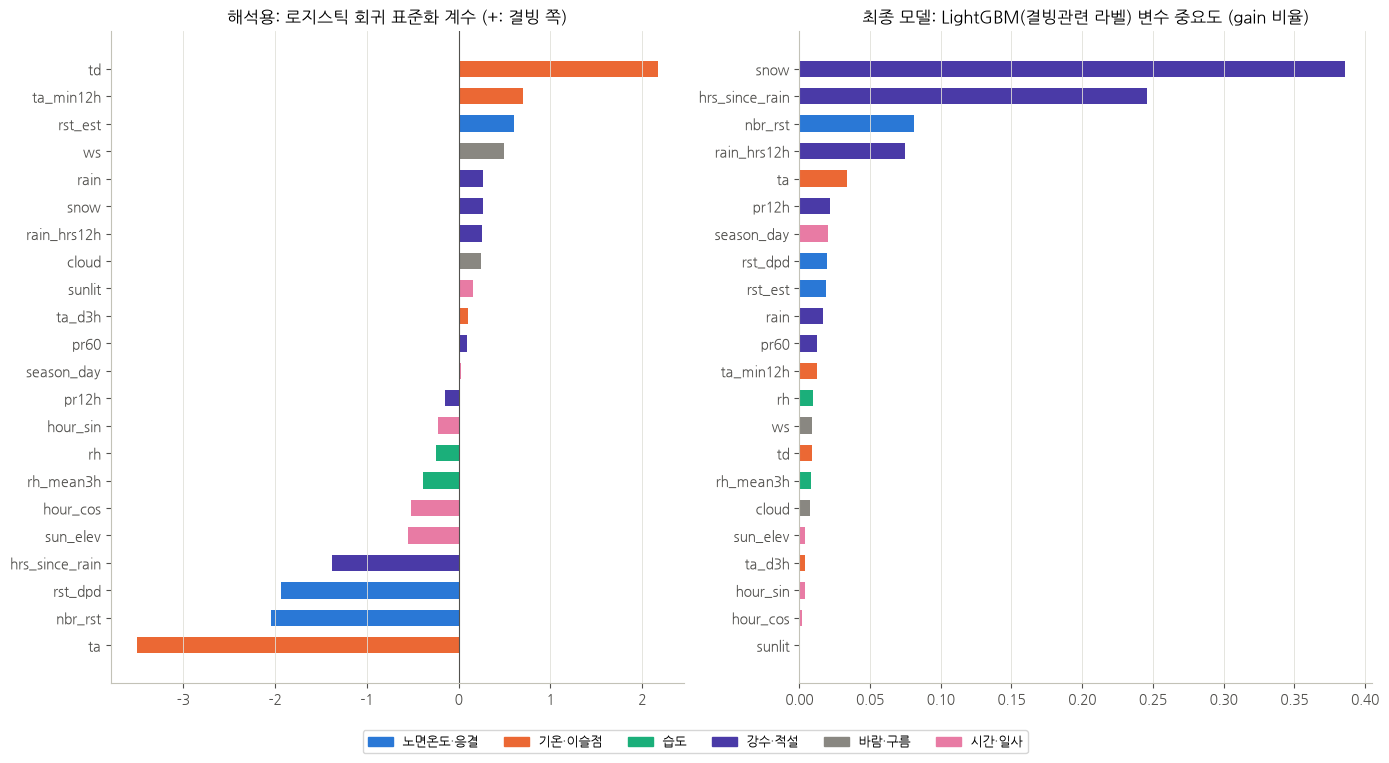

변수군을 섞었을 때 결빙관련 AP 감소 (학습 지점, 15만 행 표본)


,로지스틱 회귀,LightGBM
강수·적설,0.402,0.621
노면온도·응결,0.257,0.328
기온·이슬점,0.177,0.258
바람·구름,0.057,0.040
습도,0.044,0.054
시간·일사,0.009,0.097


In [9]:
final_cfg = CANDIDATES[FINAL]
full_models = {name: train_icing_classifier(train_all, CANDIDATES[name])
               for name in dict.fromkeys([FINAL, INTERPRET, "LightGBM(결빙관련 라벨)"])}
model = full_models[FINAL]
logit_model, lgb_model = full_models[INTERPRET], full_models["LightGBM(결빙관련 라벨)"]

FEATURE_GROUPS = {
    "노면온도·응결": ["rst_est", "rst_dpd", "nbr_rst"],
    "기온·이슬점": ["ta", "td", "ta_min12h", "ta_d3h"],
    "습도": ["rh", "rh_mean3h"],
    "강수·적설": ["rain", "pr60", "pr12h", "rain_hrs12h", "hrs_since_rain", "snow"],
    "바람·구름": ["ws", "cloud"],
    "시간·일사": ["hour_sin", "hour_cos", "sun_elev", "sunlit", "season_day"],
}
group_of = {f: g for g, fs in FEATURE_GROUPS.items() for f in fs}
GROUP_COLORS = dict(zip(FEATURE_GROUPS, ["#2a78d6", "#eb6834", "#1baf7a", "#4a3aa7", "#898781", "#e87ba4"]))

coef = pd.Series(logit_model[-1].coef_[0], index=CLS_FEATURES).sort_values()
gain = pd.Series(lgb_model.booster_.feature_importance("gain"), index=CLS_FEATURES)
gain = (gain / gain.sum()).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(14, 7.5))
axes[0].barh(coef.index, coef.values, height=0.6, color=[GROUP_COLORS[group_of[f]] for f in coef.index])
axes[0].axvline(0, color="#52514e", linewidth=0.8)
axes[0].set_title("해석용: 로지스틱 회귀 표준화 계수 (+: 결빙 쪽)")
axes[1].barh(gain.index, gain.values, height=0.6, color=[GROUP_COLORS[group_of[f]] for f in gain.index])
axes[1].set_title("최종 모델: LightGBM(결빙관련 라벨) 변수 중요도 (gain 비율)")
for ax in axes:
    ax.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in GROUP_COLORS.values()]
fig.legend(handles, GROUP_COLORS, ncol=6, loc="lower center", bbox_to_anchor=(0.5, -0.02), fontsize=9)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()


def group_permutation_drop(m, df, label="related", n_repeat=3):
    """변수군을 함께 섞었을 때 AP(결빙관련)가 떨어지는 양."""
    d = df.dropna(subset=[label])
    sample = d.sample(min(len(d), 150_000), random_state=SEED)
    y = sample[label].astype(int)
    base = average_precision_score(y, predict_icing(m, sample))
    rng = np.random.default_rng(SEED)
    out = {}
    for g, cols in FEATURE_GROUPS.items():
        drops = []
        for _ in range(n_repeat):
            shuffled = sample.copy()
            perm = rng.permutation(len(sample))
            shuffled[cols] = sample[cols].to_numpy()[perm]
            drops.append(base - average_precision_score(y, predict_icing(m, shuffled)))
        out[g] = np.mean(drops)
    return pd.Series(out)


group_imp = pd.DataFrame({"로지스틱 회귀": group_permutation_drop(logit_model, train_all),
                          "LightGBM": group_permutation_drop(lgb_model, train_all)})
coef_table = pd.DataFrame({"변수군": [group_of[f] for f in CLS_FEATURES],
                           "표준화 계수": coef.reindex(CLS_FEATURES).values,
                           "1SD당 오즈비": np.exp(coef.reindex(CLS_FEATURES).values),
                           "LightGBM gain 비율": gain.reindex(CLS_FEATURES).values}, index=CLS_FEATURES)
print("변수군을 섞었을 때 결빙관련 AP 감소 (학습 지점, 15만 행 표본)")
group_imp.sort_values("로지스틱 회귀", ascending=False).round(3)

In [10]:
coef_table.sort_values("표준화 계수").round(3)

,변수군,표준화 계수,1SD당 오즈비,LightGBM gain 비율
ta,기온·이슬점,-3.506,0.030,0.033
nbr_rst,노면온도·응결,-2.046,0.129,0.081
rst_dpd,노면온도·응결,-1.931,0.145,0.019
hrs_since_rain,강수·적설,-1.377,0.252,0.246
sun_elev,시간·일사,-0.552,0.576,0.004
hour_cos,시간·일사,-0.522,0.593,0.002
rh_mean3h,습도,-0.391,0.676,0.008
rh,습도,-0.250,0.779,0.010
hour_sin,시간·일사,-0.224,0.799,0.004
pr12h,강수·적설,-0.148,0.862,0.022


두 모델 모두 강수·적설, 노면온도·응결, 기온·이슬점 순으로 의존합니다. 변수군을 섞었을 때 결빙관련 AP 감소는 로지스틱 0.40, 0.26, 0.18이고 LightGBM 0.62, 0.33, 0.26입니다. 습도, 바람, 구름은 작고 시간·일사는 로지스틱 0.01, LightGBM 0.10입니다. Ice의 81%가 강수 중이거나 직후였던 01-6의 13장 결과와 같은 구조입니다.

로지스틱 계수의 방향은 대체로 물리적으로 해석됩니다(괄호는 표준화 계수).

- 차가울수록 결빙 쪽입니다: 기온(-3.51), 주변 RWIS 노면온도(-2.05), 노면-이슬점 차(-1.93)
- 비가 그친 지 오래될수록 비결빙 쪽입니다: 강수 후 경과 시간(-1.38, 1 표준편차당 오즈 0.25배)
- 수분 공급은 결빙 쪽입니다: 이슬점(+2.17), 강수(+0.27), 최근 12시간 강수 시간(+0.26), 적설(+0.26)
- 풍속(+0.50)은 바람이 강한 강설·한파 상황을 반영하는 것으로 보입니다.

추정 노면온도(+0.61)와 12시간 최저기온(+0.70)은 직관과 부호가 반대입니다. 서로 상관이 큰 변수끼리 계수를 나눠 가진 결과입니다. 추정 노면온도는 주변 노면온도(B1)를 구성원으로 포함해서 둘의 상관이 크고, 둘이 함께 움직일 때의 효과는 차가울수록 결빙 쪽입니다(-2.05 + 0.61 < 0).

### 이론 기반 변수 추가 실험

01-6·01-7의 13장에서 확인한 변수 5개를 더했을 때를 같은 교차검증으로 확인했습니다. 모두 추정 노면온도와 보간 기상으로 만들 수 있습니다.

| 변수 | 의미 | 근거 |
|------|------|------|
| `rst_max24h` | 직전 24시간 최고 추정 노면온도 (영상이었으면 녹은 물이 있을 수 있음) | 융해·재결빙 (01-6의 13-2) |
| `freeze_thaw24h` | 직전 24시간 동안 추정 노면온도가 0°C를 넘나든 횟수 | 동결-융해 (13-4) |
| `rst_d1h` | 1시간 노면온도 변화 (냉각 속도) | 13-4 |
| `stability` | Pasquill–Gifford 안정도 (0=D ~ 3=G) | Chapman et al. 2001 (13-5) |
| `bonanno` | Bonanno 결빙 기준 충족 여부 | 13-1 |

In [11]:
THEORY_FEATURES = ["rst_max24h", "freeze_thaw24h", "rst_d1h", "stability", "bonanno"]


def add_theory_features(df):
    """추정 노면온도·보간 기상으로 이론 기반 변수를 만든다 (지점별 시간 순서 기준)."""
    d = df.sort_values(["stn", "time"])
    g = d.groupby("stn")["rst_est"]
    above = (d["rst_est"] > 0).astype(float).where(d["rst_est"].notna())
    ws, octa = d["ws"], d["cloud"] * 0.8
    out = pd.DataFrame({
        "rst_max24h": g.transform(lambda s: s.rolling(144, min_periods=1).max()),
        "freeze_thaw24h": above.groupby(d["stn"]).transform(lambda s: s.diff().abs().rolling(144, min_periods=1).sum()),
        "rst_d1h": g.diff(6),
        "stability": np.select([ws > 5, (ws >= 3) & (octa >= 4), ws >= 3, (ws >= 2) & (octa >= 4), ws >= 2],
                               [0, 0, 1, 1, 2], 3).astype(float),
        "bonanno": bonanno_rule(d).astype(float),
    }, index=d.index)
    return out.reindex(df.index)


theory_train = train_all.join(add_theory_features(train_all))
feats_plus = CLS_FEATURES + THEORY_FEATURES
prob_plus = np.full(len(theory_train), np.nan)
t0 = time.time()
for val_stns in folds:
    m = train_icing_classifier(theory_train[~theory_train["stn"].isin(val_stns)], final_cfg, feats_plus)
    rows_val = theory_train["stn"].isin(val_stns).to_numpy()
    prob_plus[rows_val] = predict_icing(m, theory_train[rows_val], feats_plus)
thr_plus, _ = best_threshold(train_all, prob_plus)
print(f"교차검증 완료 ({time.time() - t0:.0f}s)")
pd.DataFrame({
    "AP(Ice)": [cv_table.loc[FINAL, "AP(Ice)"], average_precision_score(train_all.loc[labeled, "ice"], prob_plus[labeled])],
    "일별 F1 (빈 날 제외)": [cv_table.loc[FINAL, "일별 F1 (빈 날 제외)"], daily_f1(train_all, prob_plus >= thr_plus)],
}, index=[f"{FINAL}", f"{FINAL} + 이론 변수 5개"]).round(4)

교차검증 완료 (18s)


,AP(Ice),일별 F1 (빈 날 제외)
LightGBM(결빙관련 라벨),0.0111,0.0268
LightGBM(결빙관련 라벨) + 이론 변수 5개,0.0109,0.0403


이론 변수를 더해도 AP(Ice)는 거의 같고(0.0111, 0.0109) 일별 F1은 0.027에서 0.040으로 높아집니다. 일별 F1은 임계값과 몇 날의 결과에 크게 흔들립니다. 임계값을 전체로 고른 값으로 LightGBM 시드 5개의 일별 F1이 0.027~0.041입니다(`scripts/check_icing_models.py`). 추정 노면온도, 강수 이력, 적설, 운량, 풍속이 이미 들어 있어 같은 정보를 다른 형태로 더 넣은 것으로 보여서 변수는 늘리지 않았습니다.

## 저장

| 파일 | 내용 |
|------|------|
| `model/icing_lgbm.txt`, `model/icing_meta.json` | 최종 결빙 분류 모델과 변수, 임계값 (05에서 사용) |
| `data/processed/icing_models.joblib` | 학습 지점 14곳 전체로 학습한 후보 모델 3개 (04-3에서 사용) |
| `data/processed/icing_oof.parquet` | 학습 지점 교차검증 확률 (04-2에서 사용) |
| `data/processed/icing_cv.json` | 변수, 결빙관련 상태, 교차검증 묶음, 후보 설정, 임계값, 최종·해석용 모델 |
| `data/results/icing_cv_scores.csv`, `icing_feature_importance.csv` | 교차검증 성능, 변수 중요도 |

In [12]:
if final_cfg["kind"] == "lightgbm":
    model_file, params = "icing_lgbm.txt", PARAMS
    model.booster_.save_model(config.MODEL_DIR / model_file)
else:
    model_file, params = "icing_logistic.joblib", {"C": LOGIT_C, "class_weight": {"0": 1, "1": final_cfg["pos_weight"]}}
    joblib.dump(model, config.MODEL_DIR / model_file)
with open(config.MODEL_DIR / "icing_meta.json", "w", encoding="utf-8") as f:
    json.dump({"method": FINAL, "model_type": final_cfg["kind"], "model_file": model_file,
               "label": final_cfg["label"], "label_states": RELATED_STATES, "features": CLS_FEATURES,
               "threshold": THRESHOLD, "params": params, "pos_weight": final_cfg["pos_weight"],
               "selection": "지점 단위 교차검증 일별 F1(빈 날·결빙 없는 지점 제외)"}, f, ensure_ascii=False, indent=2)

In [13]:
# 검증 지점 예측(04-3)에 쓸 후보 모델: 학습 지점 14곳 전체로 학습
for name, cfg in CANDIDATES.items():
    if name not in full_models:
        full_models[name] = train_icing_classifier(train_all, cfg)
joblib.dump(full_models, config.PROCESSED_DIR / "icing_models.joblib")
oof_prob.assign(stn=train_all["stn"], time=train_all["time"]).to_parquet(
    config.PROCESSED_DIR / "icing_oof.parquet", index=False)
cv_info = {"features": CLS_FEATURES, "related_states": RELATED_STATES, "folds": [[int(s) for s in v] for v in folds],
           "candidates": CANDIDATES, "thresholds": thresholds, "final": FINAL, "interpret": INTERPRET}
with open(config.PROCESSED_DIR / "icing_cv.json", "w", encoding="utf-8") as f:
    json.dump(cv_info, f, ensure_ascii=False, indent=2)

cv_table.round(4).to_csv(config.RESULT_DIR / "icing_cv_scores.csv", encoding="utf-8-sig")
coef_table.join(group_imp.add_prefix("변수군 AP 감소: "), on="변수군").round(4).to_csv(
    config.RESULT_DIR / "icing_feature_importance.csv", encoding="utf-8-sig")
print("저장 완료")

저장 완료
